# Clustering với k-Means

In [9]:
import numpy as np
import matplotlib
from matplotlib import pyplot as plt

np.set_printoptions(precision=3, suppress=True)

## 1. Dữ liệu giả định

**Giả sử có 3 tập**
1. Set 1: 50 điểm
1. Set 2: 75 điểm
1. Set 3: 100 điểm

In [10]:
np.random.seed(1)
x1,y1 = np.random.normal(loc=2,scale=1,size=50), np.random.normal(loc=5,scale=1,size=50)
x2,y2 = np.random.normal(loc=5,scale=1,size=75), np.random.normal(loc=1,scale=1,size=75)
x3,y3 = np.random.normal(loc=8,scale=1,size=100), np.random.normal(loc=7,scale=1,size=100)

**=== Hiển thị 3 tập để kiểm tra ===**

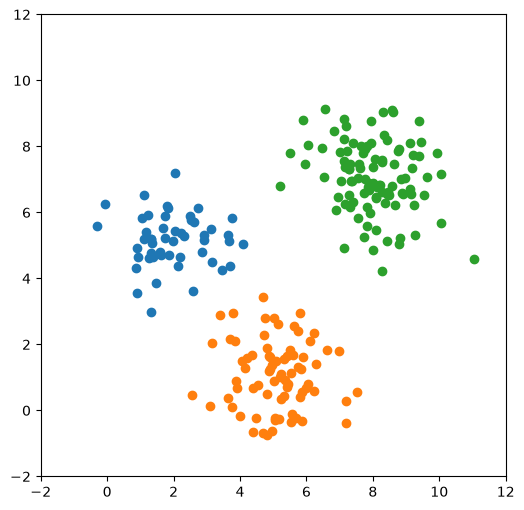

In [11]:
fig = plt.figure(figsize=(6,6))
plt.xlim([-2,12])
plt.ylim([-2,12])

plt.scatter(x1, y1)
plt.scatter(x2, y2)
plt.scatter(x3, y3)
plt.show()

### Ghép nối dữ liệu lại thành 1 tập chưa được clustered

In [12]:
dat1 = np.stack([x1, y1]).T
dat2 = np.stack([x2, y2]).T
dat3 = np.stack([x3, y3]).T

dat = np.concatenate([dat1, dat2, dat3], axis=0)


In [13]:
dat2 = np.stack([x2,y2]).T
dat3 = np.stack([x3,y3]).T

**=== Tập dữ liệu giả định có 225 dòng, 2 cột (x,y) ===**

In [14]:
print(dat.shape)
print(dat[:3])


(225, 2)
[[3.624 5.3  ]
 [1.388 4.648]
 [1.472 3.857]]


### Sắp ngẫu nhiên các dòng

In [15]:
np.random.seed(2)
np.random.shuffle(dat)

In [16]:
dat[:5]

array([[ 5.963,  7.467],
       [ 8.956,  7.053],
       [ 0.899,  3.556],
       [ 4.703, -0.674],
       [ 4.961,  1.369]])

### Kiểm tra lại với biểu đồ scatter

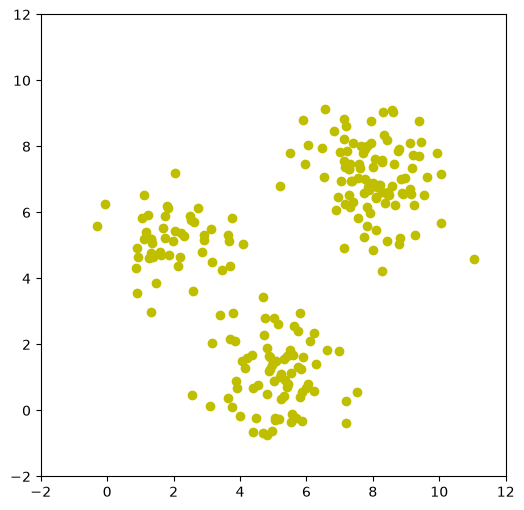

In [17]:
fig = plt.figure(figsize=(6,6))
plt.xlim([-2,12])
plt.ylim([-2,12])

plt.scatter(dat[:,0], dat[:,1], color='y')
plt.show()

## 2. Thực hiện phân cụm

### 2.1. Giả sử K=3 và tìm 3 điểm ban đầu ngẫu nhiên

In [18]:
K = 3

In [19]:
np.random.seed(30)
random_idx = np.random.choice(
    len(dat),
    size=K,
    replace=False
)


**Gán các trung tâm cho 3 điểm này**

In [20]:
centroids = dat[random_idx]
print(centroids)

[[5.338 0.438]
 [2.617 5.698]
 [4.9   1.243]]


**=== Vẽ K điểm centroids ban đầu lên biểu đồ ===**

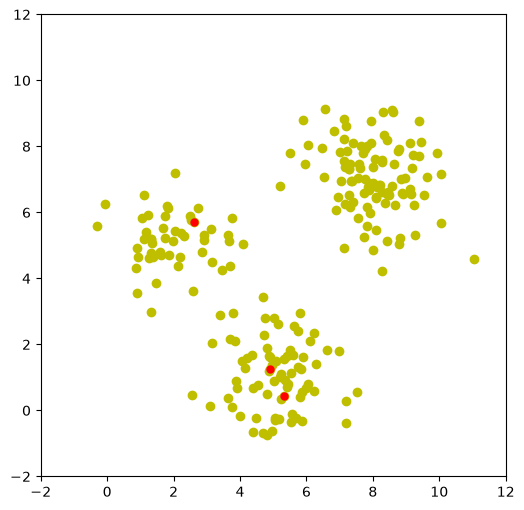

In [21]:
fig = plt.figure(figsize=(6,6))
plt.xlim([-2,12])
plt.ylim([-2,12])

plt.scatter(dat[:,0], dat[:,1], color='y')

plt.scatter(
    centroids[:,0],
    centroids[:,1],
    color='red',
    marker='.',
    s=100
)

plt.show()

### 2.2. Tiến hành gom cụm lần 1

**=== Khởi tạo K danh sách rỗng (để chứa các điểm của mỗi cluster) ===**

In [22]:
cList = [[] for _ in range(K)]
print(cList)

[[], [], []]


**=== Với mỗi sample, tìm xem nó gần điểm centroid nào nhất ===**

In [23]:
for sample in dat:
    kq = np.sum((sample - centroids)**2, axis=1)

    min_d_idx = np.argmin(kq)

    cList[min_d_idx].append(sample)
    

In [24]:
# Thử kiểm tra lại mỗi list
for i in range(K): print(len(cList[i]))

29
138
58


In [25]:
np.stack(cList[0]).shape

(29, 2)

**=== Thử lấy cluster đầu tiên ra và đánh giá ===**

In [26]:
np.stack(cList[0]).shape

(29, 2)

In [27]:
# Tọa độ của điểm centroid mới
centroid_new = np.stack(cList[0]).mean(axis=0)
print(centroid_new)

[5.584 0.19 ]


**=== Tính lại các điểm centroids ===**

In [28]:
centroids = [
    np.stack(cList[i]).mean(axis=0)
    for i in range(K)
]

centroids = np.stack(centroids)

print(centroids)

[[5.584 0.19 ]
 [5.764 6.535]
 [5.594 2.377]]


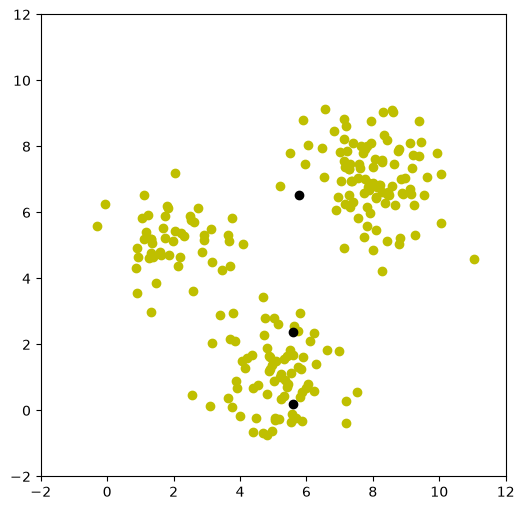

In [29]:
fig = plt.figure(figsize=(6,6))
plt.xlim([-2,12])
plt.ylim([-2,12])

plt.scatter(dat[:,0], dat[:,1], color='y')
plt.scatter(centroids[:,0], centroids[:,1], color='k')

plt.show()

### 2.3. Tiến hành gom cụm lần 2

**=== Tiếp tục khởi tạo K list rỗng để chứa các cluster mới ===**

In [30]:
cList = [[] for _ in range(K)]
for sample in dat:
    kq = np.sum((sample - centroids)**2, axis=1)
    min_d_idx = np.argmin(kq)
    cList[min_d_idx].append(sample)

# Tính giá trị của các centroids mới
centroids = [np.stack(cList[i]).mean(axis=0) for i in range(K)]
centroids = np.stack(centroids)
print(centroids)

[[5.099 0.36 ]
 [6.268 6.612]
 [4.451 2.574]]


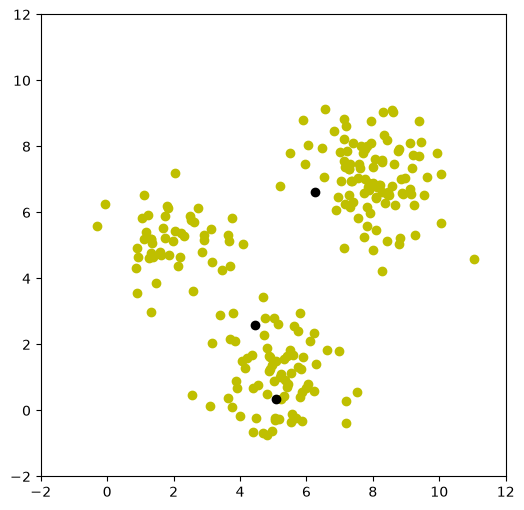

In [31]:
fig = plt.figure(figsize=(6,6))
plt.xlim([-2,12])
plt.ylim([-2,12])

plt.scatter(dat[:,0], dat[:,1], color='y')
plt.scatter(centroids[:,0], centroids[:,1], color='k')

plt.show()

### 2.4. Tiến hành gom cụm lần 3

**=== Tiếp tục khởi tạo K list rỗng để chứa các cluster mới ===**

In [32]:
cList = [[] for _ in range(K)]
for sample in dat:
    kq = np.sum((sample - centroids)**2, axis=1)
    min_d_idx = np.argmin(kq)
    cList[min_d_idx].append(sample)

centroids = [np.stack(cList[i]).mean(axis=0) for i in range(K)]
centroids = np.stack(centroids)
print(centroids)

[[5.225 0.569]
 [7.744 7.031]
 [2.898 4.079]]


**==> Nhận xét: các giá trị trung tâm gần như ít thay đổi**

In [33]:
# Lấy ra các cluster

cluster1 = np.stack(cList[0])
cluster2 = np.stack(cList[1])
cluster3 = np.stack(cList[2])

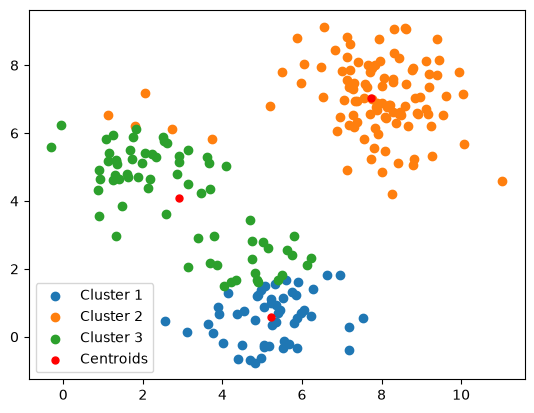

In [34]:
# Hiển thị 3 cluster lên biểu đồ
plt.scatter(cluster1[:,0], cluster1[:,1], label='Cluster 1')
plt.scatter(cluster2[:,0], cluster2[:,1], label='Cluster 2')
plt.scatter(cluster3[:,0], cluster3[:,1], label='Cluster 3')

plt.scatter(
    centroids[:,0],
    centroids[:,1],
    color='red',
    marker='.',
    s=100,
    label='Centroids'
)

plt.legend()